# Selección de variables

En un conjunto de datos con muchas variables suele haber algunas irrelevantes o redundantes. Su contribución al modelo es pequeña o nula, pero aumentan la varianza, el tiempo de entrenamiento y la dificultad de interpretar el modelo, y pueden actuar como ruido. Seleccionar un buen subconjunto de variables reduce la complejidad, mejora la interpretación y, si el subconjunto es adecuado, la exactitud {cite}`kuhn2013,james2021`.

La selección de variables no es lo mismo que la reducción de dimensionalidad. Ambas reducen el número de atributos, pero la reducción de dimensionalidad crea combinaciones nuevas de las variables (capítulo {doc}`11_ReduccionDimensionalidad`), mientras que la selección conserva o descarta las variables originales sin cambiarlas, lo que facilita la interpretación.

## Datos de ejemplo

Se construye un inventario sintético con 12 variables: cuatro realmente relacionadas con los deslizamientos (pendiente, curvatura, distancia a cauces, lluvia), dos redundantes con ellas (la elevación, correlacionada con la lluvia, y la rugosidad, correlacionada con la pendiente) y seis de puro ruido.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
plt.rcParams['figure.dpi'] = 100
rng = np.random.default_rng(4)

n = 1500
pend = rng.gamma(4, 6, n); curv = rng.normal(0, 1, n); dist = rng.exponential(250, n); lluv = rng.normal(2500, 500, n)
elev = (lluv - 1500) / 0.5 + rng.normal(0, 300, n)
rug = 0.8 * pend + rng.normal(0, 3, n)
ruido = rng.normal(0, 1, (n, 6))
eta = -5.5 + 0.11 * pend - 0.6 * curv - 0.004 * dist + 0.0011 * lluv
y = (rng.random(n) < 1 / (1 + np.exp(-eta))).astype(int)
nombres = ['pendiente', 'curvatura', 'dist_cauce', 'lluvia', 'elevacion', 'rugosidad'] + [f'ruido_{i}' for i in range(1, 7)]
X = pd.DataFrame(np.column_stack([pend, curv, dist, lluv, elev, rug, ruido]), columns=nombres)
cv = StratifiedKFold(5, shuffle=True, random_state=0)
modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
print(f'AUC con las 12 variables: {cross_val_score(modelo, X, y, cv=cv, scoring="roc_auc").mean():.3f}')

AUC con las 12 variables: 0.848


## Métodos de filtro

Los métodos de filtro evalúan cada variable según sus propiedades estadísticas, sin entrenar el modelo final: la correlación con la respuesta, una prueba estadística (t, Mann-Whitney, chi-cuadrado), la información mutua o la varianza. Son rápidos y no sobreajustan, pero evalúan las variables una por una, de modo que no detectan interacciones ni redundancias. La información mutua tiene la ventaja de captar relaciones no lineales.

In [2]:
from sklearn.feature_selection import mutual_info_classif
from scipy import stats
filtro = pd.DataFrame({
    '|correlación|': [abs(np.corrcoef(X[c], y)[0, 1]) for c in nombres],
    'p Mann-Whitney': [stats.mannwhitneyu(X.loc[y == 0, c], X.loc[y == 1, c]).pvalue for c in nombres],
    'información mutua': mutual_info_classif(X, y, random_state=0)}, index=nombres)
print(filtro.sort_values('información mutua', ascending=False).round(4))

            |correlación|  p Mann-Whitney  información mutua
rugosidad          0.4253          0.0000             0.1042
pendiente          0.4389          0.0000             0.1014
dist_cauce         0.2346          0.0000             0.0428
lluvia             0.1854          0.0000             0.0232
ruido_6            0.0420          0.1454             0.0177
elevacion          0.1662          0.0000             0.0175
curvatura          0.2401          0.0000             0.0140
ruido_4            0.0099          0.8731             0.0074
ruido_2            0.0127          0.6023             0.0000
ruido_1            0.0078          0.7740             0.0000
ruido_3            0.0158          0.6406             0.0000
ruido_5            0.0103          0.6039             0.0000


Los filtros detectan las variables relevantes, pero también la elevación y la rugosidad, que son redundantes: dan información, pero la misma que ya aportan la lluvia y la pendiente.

## Redundancia y multicolinealidad

La redundancia se detecta con la correlación entre predictores o, mejor, con el factor de inflación de la varianza (VIF), que mide cuánto aumenta la varianza del coeficiente de una variable por su colinealidad con las demás: $\mathrm{VIF}_j = 1/(1 - R_j^2)$, donde $R_j^2$ es el coeficiente de determinación de la regresión de la variable $j$ contra las otras. Un VIF cercano a 1 indica independencia; entre 1 y 5, colinealidad moderada; por encima de 5 o 10, colinealidad alta, y conviene eliminar o combinar variables.

In [3]:
def vif(df):
    Z = (df - df.mean()) / df.std()
    return pd.Series(np.diag(np.linalg.inv(np.corrcoef(Z.values, rowvar=False))), index=df.columns)
print(vif(X).round(2).sort_values(ascending=False))

lluvia        11.66
elevacion     11.66
rugosidad     11.27
pendiente     11.27
ruido_2        1.02
ruido_6        1.02
dist_cauce     1.01
curvatura      1.01
ruido_4        1.01
ruido_3        1.01
ruido_5        1.01
ruido_1        1.00
dtype: float64


## Métodos envolventes

Los métodos envolventes (wrapper) usan un modelo y su desempeño como criterio: prueban subconjuntos de variables y se quedan con el mejor. La selección hacia adelante parte de cero y agrega en cada paso la variable que más mejora el desempeño; la eliminación hacia atrás, y su versión recursiva (RFE), parte de todas y quita la menos útil. Capturan interacciones y redundancias, pero son costosos y, como eligen mirando el desempeño, pueden sobreajustar si la selección no se incluye dentro de la validación cruzada.

In [4]:
from sklearn.feature_selection import SequentialFeatureSelector
sfs = SequentialFeatureSelector(modelo, n_features_to_select='auto', tol=0.002, direction='forward', scoring='roc_auc', cv=cv)
sfs.fit(X, y)
elegidas = list(X.columns[sfs.get_support()])
print('Selección hacia adelante:', elegidas)
print(f'AUC con las variables elegidas: {cross_val_score(modelo, X[elegidas], y, cv=cv, scoring="roc_auc").mean():.3f}')

Selección hacia adelante: ['pendiente', 'curvatura', 'dist_cauce', 'lluvia']
AUC con las variables elegidas: 0.852


## Métodos embebidos

Los métodos embebidos hacen la selección durante el entrenamiento del modelo. El ejemplo clásico es el lasso {cite}`tibshirani1996`, que agrega a la función de pérdida una penalización proporcional a la suma de los valores absolutos de los coeficientes; al aumentar la penalización, los coeficientes de las variables menos útiles se vuelven exactamente cero. Los árboles y bosques aleatorios también seleccionan variables implícitamente y entregan una medida de importancia. La celda siguiente muestra la trayectoria de los coeficientes del lasso logístico a medida que la penalización disminuye.

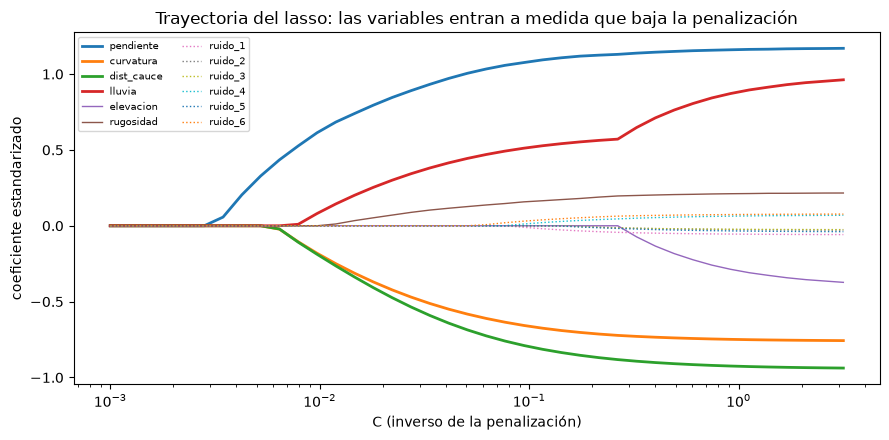

In [5]:
import warnings
warnings.filterwarnings('ignore', message='.*penalty.*')   # el argumento penalty cambia de nombre en scikit-learn >= 1.8
Cs = np.logspace(-3, 0.5, 40)
coefs = []
Xs = StandardScaler().fit_transform(X)
for C in Cs:
    m = LogisticRegression(penalty='l1', C=C, solver='liblinear').fit(Xs, y)
    coefs.append(m.coef_[0])
coefs = np.array(coefs)
fig, ax = plt.subplots(figsize=(9, 4.5))
for j, nom in enumerate(nombres):
    ax.plot(Cs, coefs[:, j], label=nom, lw=2 if j < 4 else 1, ls='-' if j < 6 else ':')
ax.set_xscale('log'); ax.set_xlabel('C (inverso de la penalización)'); ax.set_ylabel('coeficiente estandarizado')
ax.legend(fontsize=7, ncol=2); ax.set_title('Trayectoria del lasso: las variables entran a medida que baja la penalización')
plt.tight_layout(); plt.show()

Con penalización fuerte (a la izquierda) solo sobreviven las variables más informativas; las de ruido entran al final y con coeficientes pequeños. Entre las redundantes, el lasso tiende a quedarse con una y descartar la otra.

## Recomendaciones

Los filtros son una buena primera revisión, sobre todo con muchas variables. Los envolventes y embebidos dan mejores subconjuntos, pero toda selección que use la respuesta debe hacerse dentro de la validación cruzada, porque si se seleccionan las variables con todos los datos y luego se valida, el desempeño estimado es optimista. Por encima de cualquier método, el conocimiento del problema es el mejor criterio: una variable sin explicación física que resulta muy importante merece sospecha antes que entusiasmo.

## Para profundizar

Los capítulos 18 y 19 de {cite}`kuhn2013` tratan la importancia y la selección de variables, y la sección 6.1 de {cite}`james2021`, la selección de subconjuntos. El notebook 06 del curso aplica filtros estadísticos a un inventario real.